# CreditRisk+ and the granularity adjustment

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- describe the CreditRisk+ model, in which defaults are Poisson counts driven by a Gamma sector factor, and say how its loss distribution is computed without simulation;
- run the stable recursion on the illustrative book, check its first probability against a closed form, and read VaR and expected shortfall from the exact distribution;
- show on a constructed stress portfolio why the original Panjer-type recursion is kept only as a comparison;
- state the granularity adjustment of Gordy and Lutkebohmert, reproduce its test vector, and compute it for the book from the IRB capital of each group;
- read the gap between the infinitely granular formula and a finite, concentrated book, and say where the adjustment over-states it;
- test the recursion against a Monte Carlo sample of the same model.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two of the five loan-type files of case C10 (owner: this repository; the loss rates behind the fits come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- `data/derived/C10/commercial-industrial.json`: the illustrative book of 1,120 names (`outputs.portfolio`), the committed CreditRisk+ rung (`outputs.rungs`, with its parameters and diagnostics), the granularity block (`outputs.granularity`) and the test row of the recursion against Monte Carlo (`tests`);
- `data/derived/C10/credit-cards.json`: the same blocks for the credit-card book, used in Step 5 because its granularity table carries the exact CreditRisk+ answer that the commercial file lacks.

The book is constructed and labelled `illustrative`, never a bank's. The next cell loads both files and prints what the committed CreditRisk+ rung used.

In [2]:
# Load the two artifacts and print what the committed CreditRisk+ rung used
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
cards = json.loads((ROOT / "data" / "derived" / "C10" / "credit-cards.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}
crp = rungs["c4-creditrisk-plus"]

print("baked by riskvalidation", doc["provenance"]["riskvalidation_version"])
print("book:", book["label"], "|", book["n_names"], "names |", f"{book['total_ead']:,.0f}", book["currency"])
print("CreditRisk+ parameters:", [(p["name"], p["value"]) for p in crp["parameters"]])
print("CreditRisk+ diagnostics:", [(d["name"], d["value"]) for d in crp["diagnostics"]])

baked by riskvalidation 1.0.1
book: illustrative | 1120 names | 100,000,000 USD
CreditRisk+ parameters: [('sigma2', 0.552065603), ('loss_unit', 1000.0)]
CreditRisk+ diagnostics: [('n_max', 12728.0), ('tail_mass_left_out', -1.54321e-13), ('expected_loss', 409720.505), ('unit_rounding', 0.0)]


## Method

### Step 1: the CreditRisk+ model

CreditRisk+ is the actuarial counterpart of the copula models. Exposures are whole multiples $\nu_i$ of a **loss unit** (here 1,000 USD of loss, that is, exposure times LGD). The number of defaults of name $i$ is Poisson with an intensity that depends on a **sector factor** $S$ with a Gamma distribution of mean 1 and variance $\sigma^2$, and the portfolio loss in units is $X=\sum_i \nu_i Y_i$. With one sector and no idiosyncratic weight, the intensity of name $i$ is $p_i S$. The probability generating function of the loss, the object from which the distribution is computed, is (Haaf, Reiss and Schoenmakers, 2004, https://doi.org/10.21314/jor.2004.097):

$$G(z) = \exp\!\left(-\frac{1}{\sigma^2}\ln\!\left[1-\sigma^2\sum_i p_i\,(z^{\nu_i}-1)\right]\right)$$

The model has limits to remember: default mode only, deterministic recoveries in the basic model, and a Poisson approximation that can give several defaults of one obligor when a PD is large. The Gamma variance is a parameter the case sets by moment matching: $\sigma^2$ is the variance of the Vasicek default rate of notebook 01 over the squared PD, $\sigma^2=(E[p(Z)^2]-\mathrm{PD}^2)/\mathrm{PD}^2$. This is a calibration choice, not a risk measure. The next cell builds the engine's input from the groups, using the committed $\sigma^2$, and recomputes $\sigma^2$ by numerical integration of the conditional PD of notebook 01 to check the committed value.

In [3]:
# Build the CreditRisk+ input from the groups and check the committed sigma squared by numerical integration
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr

loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
lgd = book["lgd_mean"]

ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
units = np.rint(ead * lgd / loss_unit).astype(int)
inp = cr.CreditRiskPlusInput(nu=units, pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
                             sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
print("names:", ead.size, "| exposure bands (loss units):", sorted(set(units.tolist())), "| total units:", int(units.sum()))
print("rounding of exposure x LGD to whole units:", float(np.abs(units * loss_unit - ead * lgd).max()))
print("expected number of defaults:", round(float(pd_names.sum()), 4))

second_moment, _ = integrate.quad(lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z), -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
print("sigma^2 committed:", sigma2, "| by integration:", round((second_moment - pd_hat ** 2) / pd_hat ** 2, 9))

names: 1120 | exposure bands (loss units): [9, 180, 900] | total units: 45000
rounding of exposure x LGD to whole units: 0.0
expected number of defaults: 16.2877
sigma^2 committed: 0.552065603 | by integration: 0.552065603


### Step 2: the stable recursion and its exact distribution

Taking logarithms of the generating function and expanding in powers of $z$ gives a recursion for the probabilities $p_n=P(X=n)$. Write $\ln G(z)=\sum_{j\ge 0} a_j z^j$; then $p_0=e^{a_0}$ and $n\,p_n=\sum_{j=1}^{n} j\,a_j\,p_{n-j}$. In the stable form of Haaf, Reiss and Schoenmakers (2004) every coefficient $a_j$ for $j\ge1$ is nonnegative, so no subtraction of terms of opposite sign occurs and no probability can come out negative. The engine's `pmf_stable` computes $p_0,\dots,p_{n_{\max}}$ and leaves the tail mass out. A closed form checks it: with one sector, $P(X=0)=G(0)=(1+\sigma^2\mu)^{-1/\sigma^2}$ where $\mu=\sum_i p_i$ is the expected number of defaults. `measures_from_pmf` then reads VaR and expected shortfall on the unit grid with the discrete Acerbi and Tasche estimator. The next cell runs the recursion up to the grid length the pipeline used, checks $p_0$ and the missing mass, and compares the measures with the committed rung.

In [4]:
# Run the stable recursion, check P(X = 0) against its closed form and compare VaR and ES with the committed rung
n_max = int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max"))
pmf = cr.pmf_stable(inp, n_max)
mu = float(pd_names.sum())
print("n_max:", n_max, "| mass on the grid:", round(float(pmf.sum()), 12), "| negative entries:", int((pmf < 0).sum()))
print("P(X = 0) recursion:", f"{pmf[0]:.12e}", "| closed form:", f"{(1 + sigma2 * mu) ** (-1 / sigma2):.12e}")

measures = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for m, c in zip(measures, crp["measures"]):
    print(f"q = {m.level}: EL {m.el:,.0f} | VaR {m.var:,.0f} | ES {m.es:,.0f} | capital {m.ec:,.0f}   committed: VaR {c['var']:,.0f} | ES {c['es']:,.0f}")

n_max: 12728 | mass on the grid: 1.0 | negative entries: 0
P(X = 0) recursion: 1.546187529854e-02 | closed form: 1.546187529854e-02
q = 0.99: EL 409,721 | VaR 2,079,000 | ES 2,514,778 | capital 1,669,279   committed: VaR 2,079,000 | ES 2,514,778
q = 0.999: EL 409,721 | VaR 3,078,000 | ES 3,506,025 | capital 2,668,279   committed: VaR 3,078,000 | ES 3,506,025


The recursion gives the whole distribution at once. The next cell draws its exceedance probability, the chance of a loss above each level, next to two committed references: the Gaussian copula with one factor (a Monte Carlo of a million scenarios) and the large-portfolio limit. CreditRisk+ with the moment-matched $\sigma^2$ and the Gaussian copula describe the same book with different assumptions, and the two curves are close in the body and part in the far tail.

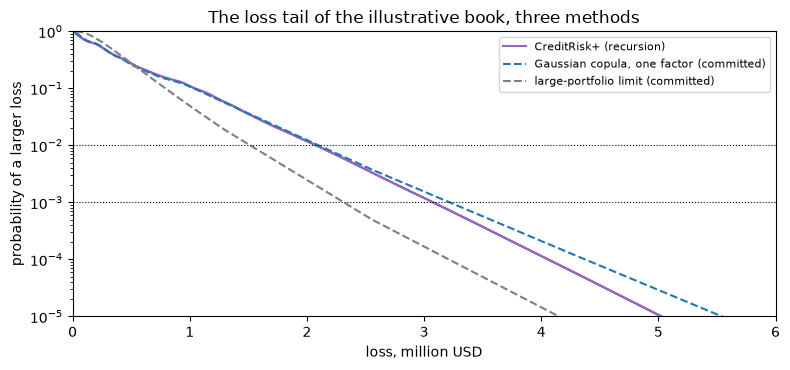

In [5]:
# Draw the exceedance probability of CreditRisk+ against the committed Gaussian copula and the large-portfolio limit
fig, ax = plt.subplots(figsize=(8, 3.8))
loss_grid = np.arange(pmf.size) * loss_unit
ax.plot(loss_grid / 1e6, 1 - np.cumsum(pmf), label="CreditRisk+ (recursion)", color="tab:purple")
for rid, label, color in (("c2-gaussian-1f", "Gaussian copula, one factor (committed)", "tab:blue"), ("c1-lhp", "large-portfolio limit (committed)", "tab:gray")):
    curve = rungs[rid]["distribution"]
    ax.plot(np.array(curve["loss"]) / 1e6, 1 - np.array(curve["cdf"]), label=label, color=color, linestyle="--")
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 6)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("probability of a larger loss")
ax.set_title("The loss tail of the illustrative book, three methods")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 3: why the original recursion is kept only as a comparison

The recursion of the original CreditRisk+ document clears the denominators of the generating function by multiplying them out. That subtracts terms of opposite sign, and round-off can then give negative probabilities (the instability noted by Haaf, Reiss and Schoenmakers, 2004). The engine's `pmf_panjer` has the same signature as `pmf_stable` and is kept only to show this; it clips nothing. On the book of this case, with one sector, the two agree to rounding. The next cell compares them there and then on a **constructed stress portfolio**: 30,000 names in 5 exposure bands, 8 sectors with Gamma variances from 0.02 to 12, and about 1,800 expected defaults, drawn from a seeded generator. The stress portfolio is synthetic, built here to show the failure, and is not a case of the product.

In [6]:
# Compare the stable and the Panjer recursions on the case book and on a constructed stress portfolio
panjer = cr.pmf_panjer(inp, n_max)
print("case book: largest difference", f"{np.abs(panjer - pmf).max():.1e}", "| negative Panjer entries:", int((panjer < 0).sum()))

rng = np.random.default_rng(3)
n_stress, n_sectors = 30_000, 8
stress_units = rng.integers(1, 6, size=n_stress)
stress_pd = rng.uniform(0.03, 0.09, size=n_stress)
stress_w = rng.dirichlet(np.ones(n_sectors + 1), size=n_stress)
stress = cr.CreditRiskPlusInput(
    nu=stress_units, pd=stress_pd, w0=stress_w[:, 0], weights=stress_w[:, 1:],
    sigma2=np.array([0.02, 0.2, 0.8, 1.5, 3.0, 6.0, 9.0, 12.0]), loss_unit=1.0, currency="USD")
stress_grid = 6000
stable_s = cr.pmf_stable(stress, stress_grid)
panjer_s = cr.pmf_panjer(stress, stress_grid)
outside = lambda p: int(((p < 0) | (p > 1)).sum())
print("stress portfolio:", n_stress, "names,", n_sectors, "sectors, expected defaults", round(float(stress.pd.sum())))
print("stable: entries outside [0, 1]", outside(stable_s), "| smallest entry", f"{stable_s.min():.2e}", "| sum of the probabilities", round(float(stable_s.sum()), 3))
print("Panjer: entries outside [0, 1]", outside(panjer_s) > 0, "| negative entries", int((panjer_s < 0).sum()) > 0, "| sum of the probabilities within [0, 1]", bool(0 <= panjer_s.sum() <= 1))

case book: largest difference 1.6e-17 | negative Panjer entries: 0
stress portfolio: 30000 names, 8 sectors, expected defaults 1802
stable: entries outside [0, 1] 0 | smallest entry 1.58e-137 | sum of the probabilities 0.721
Panjer: entries outside [0, 1] True | negative entries True | sum of the probabilities within [0, 1] False


### Step 4: the granularity adjustment

The large-portfolio formula assumes names so small that the idiosyncratic risk disappears. A concentrated book keeps some of it, and capital must be higher. Gordy and Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf) give a simplified adjustment, a share of exposure, built on the single-factor CreditRisk+ model with a Gamma factor of mean 1 and variance $1/\xi$:

$$\mathrm{GA}=\frac{1}{2K^*}\sum_i s_i^2\,C_i\,\big(\delta\,(K_i+R_i)-K_i\big),\qquad \delta=(\alpha_q-1)\left(\xi+\frac{1-\xi}{\alpha_q}\right)$$

where $s_i$ is the exposure share, $K_i$ the capital of name $i$ per unit of exposure, $K^*=\sum_i s_iK_i$, $R_i=E[\mathrm{LGD}_i]\,\mathrm{PD}_i$ the reserve, $C_i=(V[\mathrm{LGD}_i]+E[\mathrm{LGD}_i]^2)/E[\mathrm{LGD}_i]$, $V[\mathrm{LGD}_i]=\gamma\,E[\mathrm{LGD}_i](1-E[\mathrm{LGD}_i])$ and $\alpha_q$ the $q$-quantile of the Gamma factor (equations 11, 15, 16 and 17 of the paper). The paper states a test vector: $\xi=0.25$ and $q=0.999$ give $\delta=4.83$. The engine's `delta` and `gamma_quantile` compute it; the next cell reproduces the vector and shows how $\delta$ moves with $\xi$ and $q$.

In [7]:
# Reproduce the paper test vector delta = 4.83 and show delta for other precisions and levels
from riskvalidation.portfolio import granularity as gr

xi_ref = out["granularity"]["xi"]
print("xi =", xi_ref, "| q = 0.999 | alpha_q =", round(gr.gamma_quantile(xi_ref, 0.999), 4), "| delta =", round(gr.delta(xi_ref, 0.999), 4), "| paper:", out["granularity"]["delta_reference"], "| committed:", out["granularity"]["levels"][1]["delta"])
print(f"{'xi':>6s} {'q = 0.99':>10s} {'q = 0.999':>10s} {'q = 0.9995':>11s}")
for xi in (0.25, 0.5, 1.0, 2.0):
    print(f"{xi:6.2f} {gr.delta(xi, 0.99):10.4f} {gr.delta(xi, 0.999):10.4f} {gr.delta(xi, 0.9995):11.4f}")

xi = 0.25 | q = 0.999 | alpha_q = 17.5058 | delta = 4.8336 | paper: 4.83 | committed: 4.83360126
    xi   q = 0.99  q = 0.999  q = 0.9995
  0.25     2.8568     4.8336      5.4482
  0.50     3.2421     5.3676      6.0166
  1.00     3.6052     5.9078      6.6009
  2.00     3.9396     6.4500      7.1987


Now the adjustment for the book. The capital $K_i$ of each name is the IRB capital of the name's group at its own PD, with an LGD of 45% and a maturity of 2.5 years (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm), as the regulatory algorithm of the paper prescribes. The engine's `capital_requirement` returns it and `granularity_adjustment` applies the formula, with the paper's $\xi=0.25$ and $\gamma=0.25$ read from the artifact. The adjustment is a share of exposure; adding it to the large-portfolio VaR gives the capital of the book with its concentration.

In [8]:
# Compute the granularity adjustment of the book from the IRB capital of each group and compare with the committed block
from riskvalidation.portfolio.portfolio import lhp_measures
from riskvalidation.regulatory.irb import capital_requirement

gran = out["granularity"]
k_group = {g["id"]: float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k) for g in groups}
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
print("K by group (IRB capital per unit of exposure):", {k: round(v, 5) for k, v in k_group.items()})

for level, committed in zip((0.99, 0.999), gran["levels"]):
    res = gr.granularity_adjustment(share, k_names, pd_names, np.full(ead.size, lgd), gran["gamma"], gran["xi"], level)
    var_lhp = lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, (level,))[0].var
    print(f"q = {level}: delta {res.delta:.4f} | K* {res.k_star:.6f} | GA {res.ga:.8f} (committed {committed['ga']:.8f}) | in money {res.ga * book['total_ead']:,.0f}")
    print(f"        large-portfolio VaR {var_lhp:,.0f} | with the adjustment {var_lhp + res.ga * book['total_ead']:,.0f} | GA over the large-portfolio VaR {res.ga * book['total_ead'] / var_lhp:.3f}")

K by group (IRB capital per unit of exposure): {'g-large': 0.05598, 'g-mid': 0.07416, 'g-small': 0.08477}
q = 0.99: delta 2.8568 | K* 0.069012 | GA 0.00481771 (committed 0.00481771) | in money 481,771
        large-portfolio VaR 1,500,956 | with the adjustment 1,982,727 | GA over the large-portfolio VaR 0.321
q = 0.999: delta 4.8336 | K* 0.069012 | GA 0.00982976 (committed 0.00982976) | in money 982,976
        large-portfolio VaR 2,298,833 | with the adjustment 3,281,809 | GA over the large-portfolio VaR 0.428


### Step 5: the adjustment against the exact answer for a finite book

The adjustment is an asymptotic approximation, proportional to the HHI of exposure shares, so for $n$ identical names $\mathrm{GA}\times n$ is constant. How good is it for a small book? For $n$ identical names the single-factor CreditRisk+ model of the paper can be solved exactly with the recursion: the weight of the names on the factor is $\omega=K/(E[\mathrm{LGD}]\,\mathrm{PD}\,(\alpha_q-1))$ (equation 13 of the paper, solved for $\omega$), the Gamma variance is $1/\xi$, and the exact adjustment is the difference between the book's exact VaR share, $E[\mathrm{LGD}]\,\mathrm{VaR}_{\text{units}}/n$, and the infinitely granular one, $E[\mathrm{LGD}]\,\mathrm{PD}+K$. The condition is $0<\omega\le1$. For the commercial book $\omega$ is above 1, so the recursion was not run and the committed file has no exact answer; the credit-card book satisfies it. The next cell computes, for credit cards, the adjustment and the exact gap for $n=10$, $100$ and $1{,}000$ names, and the commercial $\omega$.

In [9]:
# For n identical names compare the adjustment with the exact CreditRisk+ gap (credit cards), and show the commercial omega
def exact_gap(pd_i, k_i, n, q=0.999, xi=0.25, lgd_i=0.45):
    """The weight omega on the factor and the exact adjustment of n identical names by the recursion"""
    omega_i = k_i / (lgd_i * pd_i * (gr.gamma_quantile(xi, q) - 1.0))
    if not 0.0 < omega_i <= 1.0:
        return omega_i, None
    names = cr.CreditRiskPlusInput(nu=np.ones(n, dtype=np.int64), pd=np.full(n, pd_i), w0=np.full(n, 1.0 - omega_i), weights=np.full((n, 1), omega_i),
                                   sigma2=np.array([1.0 / xi]), loss_unit=1.0, currency="USD")
    grid = max(40, 4 * n)
    while True:
        p = cr.pmf_stable(names, grid)
        if p.sum() >= q + 1e-6 or grid >= 20 * n:
            break
        grid *= 2
    var_units = cr.measures_from_pmf(p, 1.0, (q,))[0].var
    return omega_i, max(lgd_i * var_units / n - (lgd_i * pd_i + k_i), 0.0)

c_out = cards["outputs"]
pd_cards = c_out["fit"]["maximum_likelihood"]["pd"]["estimate"]
k_cards = float(capital_requirement(c_out["irb_reference"]["asset_class"], pd_cards, lgd, regime="basel3").k)
committed_rows = {r["n_names"]: r for r in c_out["granularity"]["by_n_names"]}

print("credit cards: PD", round(pd_cards, 5), "| K", round(k_cards, 5))
print(f"{'names':>7s} {'GA (formula)':>14s} {'GA x n':>9s} {'exact gap':>14s} {'committed exact':>16s} {'formula / exact':>16s}")
for n_names in (10, 100, 1000):
    formula = gr.granularity_adjustment(np.full(n_names, 1 / n_names), np.full(n_names, k_cards), np.full(n_names, pd_cards), np.full(n_names, lgd), gran["gamma"], gran["xi"], 0.999).ga
    omega_c, truth = exact_gap(pd_cards, k_cards, n_names)
    print(f"{n_names:7d} {formula:14.6f} {formula * n_names:9.4f} {truth:14.6f} {committed_rows[n_names]['truth_ga']:16.6f} {formula / truth:16.2f}")
k_commercial = float(capital_requirement("corporate", pd_hat, lgd, regime="basel3", maturity=2.5).k)
print("commercial: omega implied by K:", round(exact_gap(pd_hat, k_commercial, 100)[0], 3), "(outside (0, 1]: no exact answer)")

credit cards: PD 0.04228 | K 0.03917
  names   GA (formula)    GA x n      exact gap  committed exact  formula / exact
     10       0.181580    1.8158       0.121804         0.121804             1.49
    100       0.018158    1.8158       0.013804         0.013804             1.32
   1000       0.001816    1.8158       0.001204         0.001204             1.51
commercial: omega implied by K: 1.055 (outside (0, 1]: no exact answer)


### Step 6: the recursion against a Monte Carlo of the same model

The exact distribution should agree with a simulation of the same Poisson-Gamma model. The engine's `crp_recursion_vs_mc` measures the Kolmogorov distance between the recursion's distribution function and a sample's, with the asymptotic Kolmogorov law for its p-value (conservative for a discrete distribution, the contract's definition); it is red whatever the p-value if any probability is negative. The comparator is a plain simulation written here from the model's definition, an independent check and not a second engine: draw the Gamma factor, and for each group draw a Poisson count with intensity (names times PD times factor) and multiply by the group's loss units. The next cell draws 100,000 scenarios with the pipeline's seed and compares with the committed row of 400,000.

In [10]:
# Simulate the Poisson-Gamma model and test the recursion against the sample, then compare with the committed row
from riskvalidation.validation.portfolio import crp_recursion_vs_mc

rng_crp = np.random.default_rng(np.random.PCG64(4006))
n_mc = 100_000
factor = rng_crp.gamma(shape=1.0 / sigma2, scale=sigma2, size=n_mc)
sample_units = np.zeros(n_mc, dtype=np.int64)
first = 0
for g in groups:
    sample_units += int(units[first]) * rng_crp.poisson(g["n_names"] * g["pd"] * factor)
    first += g["n_names"]

verdict = crp_recursion_vs_mc(pmf, sample_units, model_id="m-creditrisk-plus")
row = next(t for t in doc["tests"] if t["test_id"] == "portfolio.crp_recursion_vs_mc")
print("scenarios:", n_mc, "| Kolmogorov distance:", round(verdict.statistic, 5), "| p-value:", round(verdict.p_value, 4), "|", verdict.light.value, "| negative entries:", verdict.extras["negative_entries"])
print("committed row:", row["n"], "scenarios | D", round(row["statistic"], 5), "| p-value", round(row["p_value"], 4), "|", row["light"])

scenarios: 100000 | Kolmogorov distance: 0.00398 | p-value: 0.0843 | green | negative entries: 0
committed row: 400000 scenarios | D 0.00126 | p-value 0.5535 | green


The last cell puts the methods side by side. For the same book and the same fitted PD and correlation it lists the committed 99.9% VaR of each rung that computes one: the large-portfolio limit, CreditRisk+, the Gaussian copula by Monte Carlo and by importance sampling (notebook 05), and the large-portfolio limit plus the granularity adjustment. The gap between the first and the others is the price of a finite, concentrated book.

In [11]:
# List the committed 99.9% VaR of each rung that computes one and its ratio to the large-portfolio limit
base = rungs["c1-lhp"]["measures"][1]["var"]
print(f"{'rung':22s} {'VaR 99.9%':>12s} {'ratio to the limit':>22s}")
for rid in ("c1-lhp", "c4-creditrisk-plus", "c2-gaussian-1f", "c6-is-gaussian", "c5-granularity"):
    var999 = rungs[rid]["measures"][1]["var"]
    print(f"{rid:22s} {var999:12,.0f} {var999 / base:22.3f}")
print("granularity adjustment at 99.9% in money:", f"{gran['levels'][1]['ga_money']:,.0f}", "| impact.ga_999_share:", round(doc["impact"]["ga_999_share"]["value"], 5))

rung                      VaR 99.9%     ratio to the limit
c1-lhp                    2,298,834                  1.000
c4-creditrisk-plus        3,078,000                  1.339
c2-gaussian-1f            3,177,000                  1.382
c6-is-gaussian            3,204,000                  1.394
c5-granularity            3,281,809                  1.428
granularity adjustment at 99.9% in money: 982,976 | impact.ga_999_share: 0.00983


## Results

- **The recursion gives the whole loss distribution exactly, and its anchor holds.** For the 1,120-name book the stable recursion puts mass 1.0 on a grid of 12,728 units with no negative entry, and its first probability, 1.546187529854e-02, equals the closed form $(1+\sigma^2\mu)^{-1/\sigma^2}$ to every digit printed. The 99% and 99.9% VaR are 2,079,000 and 3,078,000 USD, the expected shortfalls 2,514,778 and 3,506,025 USD, and the 99.9% capital 2,668,279 USD, equal to the committed rung (baked by engine 0.7.0, installed 0.8.1). The moment-matched $\sigma^2$ of 0.552065603 is also reproduced by numerical integration.
- **The original Panjer recursion is unstable where it counts.** On the case book it agrees with the stable one to 1.6e-17 and has no negative entry, so the case does not show the problem. On the constructed stress portfolio (30,000 names, 8 sectors) it returns negative probabilities and entries outside [0, 1], and its probabilities do not add to a value in [0, 1], while the stable recursion has no entry outside [0, 1] (its sum, 0.721, is below 1 only because the grid of 6,000 units cuts the tail, which the engine leaves out and never adds back). That is why the engine ships the Panjer form only as a comparison.
- **The granularity adjustment reproduces the paper and adds 32% to 43% to the large-portfolio VaR.** The test vector holds: $\delta=4.8336$ at $\xi=0.25$ and $q=0.999$ against the paper's printed 4.83. With the IRB capital of each group (0.05598, 0.07416 and 0.08477 per unit of exposure, giving $K^*=0.069012$) the adjustment is 0.00481771 of exposure at 99% and 0.00982976 at 99.9%, equal to the committed values, that is 481,771 and 982,976 USD. At 99.9% it is 42.8% of the large-portfolio VaR of 2,298,833 USD, and the large-portfolio VaR with the adjustment is 3,281,809 USD.
- **The finite book needs more capital than the limit says, by any method.** At 99.9%, relative to the large-portfolio limit, CreditRisk+ is 1.339 times, the Gaussian copula by Monte Carlo 1.382, by importance sampling 1.394, and the limit plus the adjustment 1.428. The book has 104 effective names. The four are not like for like: CreditRisk+ and the adjustment rest on a Gamma factor (the adjustment on the paper's $\xi=0.25$ and the IRB capital), the Gaussian copula on a normal factor.
- **Against the exact answer, the adjustment over-states the gap.** For identical credit-card names the formula times $n$ is constant, 1.8158, as the theory says, and the exact CreditRisk+ gap is 0.121804, 0.013804 and 0.001204 at 10, 100 and 1,000 names, reproducing the committed values. The formula is 1.49, 1.32 and 1.51 times the exact gap. For the commercial book the implied weight on the factor is 1.055, outside (0, 1], so there is no exact answer and the committed file records the reason instead of a number.
- **The recursion agrees with a simulation of its own model.** With 100,000 scenarios the Kolmogorov distance is 0.00398 (p = 0.084, green) and with the committed 400,000 it is 0.00126 (p = 0.55, green); no probability is negative. The test is on the distribution's shape, not on a quantile, and its asymptotic p-value is conservative for a discrete distribution.

What this notebook does not show: how the capital splits among the groups (notebook 05), whether the adjustment is conservative for the commercial book (no exact answer exists for it), or which model is right. CreditRisk+ and the copulas are different assumptions about the same book.

## Summary

- CreditRisk+ models defaults as Poisson counts driven by a Gamma factor; its loss distribution comes from a recursion on the generating function, with no simulation, and `pmf_stable` is exact and nonnegative.
- The original Panjer recursion subtracts terms of opposite sign and fails on a large multi-sector portfolio; the engine keeps it only as a comparison.
- The granularity adjustment (`granularity_adjustment`, `delta`) reproduces the paper's test vector and adds 42.8% to the large-portfolio VaR of the book at 99.9%.
- Against the exact CreditRisk+ gap of identical names, the formula over-states by 32% to 51% on the credit-card book, and a book whose implied factor weight is outside (0, 1] has no exact answer.
- `crp_recursion_vs_mc` tests the recursion against a simulation of its own model.

**What to try next.** Change the number of names in Step 5 to 20 and 500 for credit cards and compare the formula with the exact gap. Then open notebook 05, where the capital of the book is split among its groups.

## References

- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. and Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Acerbi, C. and Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework, the original model document: not accessed by the persisted research (UNVERIFIED primary); the model statement is verified from Haaf, Reiss and Schoenmakers (2004).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.4 and H.5 (CreditRisk+ and the granularity adjustment).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.